# Titanic: predicting survival

Kaggle's [Titanic competition](https://www.kaggle.com/competitions/titanic): predict which passengers survived from their ticket, family and personal details.

**Contents**
1. Setup: imports and data
2. Exploratory analysis (done in R)
3. Feature engineering
4. Random forest: comparing feature sets, then tuning
5. XGBoost: baseline, tuning, final model
6. Explaining the model with SHAP
7. Error analysis
8. Feature experiments: `TicketCount`, `WomanOrChild`
9. Support vector machines: linear and RBF
10. Results summary

Every model is scored with the same 5-fold stratified cross-validation (`skf`), so the scores can be compared directly.

## 1. Setup

The data was downloaded once with `kagglehub` and copied into `data/`:

```python
import kagglehub
import pandas as pd

# Download latest version
path = kagglehub.competition_download('titanic')

print("Path to competition files:", path)
```

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier
import shap

In [7]:
train_data = pd.read_csv("data/train.csv")
test_data = pd.read_csv("data/test.csv")

## 2. Exploratory analysis (done in R)

I did some EDA and data analysis with R earlier. I investigated how each passenger feature relates to survival, using the training set only.

**Setup**
- Loaded `train.csv` and `test.csv` with `readr`, and standardised the column names with `janitor::clean_names()` (e.g. `SibSp` became `sib_sp`).
- Converted `survived`, `pclass` and `sex` to factors so the plots treat them as categories.

**What I looked at**
- **Age vs survival:** a beeswarm plot of every passenger's age, split by survived / didn't survive.
- **Age vs survival by sex:** boxplots of age by survival outcome, one panel per sex.
- **Passenger class:** stacked proportion bars showing the survival rate in 1st, 2nd and 3rd class.
- **Siblings/spouses aboard (`sib_sp`):** survival-rate bars, plus a count of passengers at each value to check how many people sit behind each bar.
- **Parents/children aboard (`parch`):** survival-rate bars.
- **Fare:** a histogram of fares coloured by survival.
- **Fare vs age:** a scatter plot coloured by survival, to look at both together.

**Takeaways**
- Passengers who paid higher fares, had fewer siblings/parents aboard, and were younger seem to have a higher survival rate.
- These findings shaped the feature engineering below (`FamilySize`, `IsAlone`, `Title`) and the features chosen for the models.

The R code behind that analysis, kept for reference. It doesn't run on this notebook's Python kernel.

```r
library(ggplot2)
library(dplyr)
library(tidyverse)
install.packages("janitor")
library(ggbeeswarm)
library(janitor)

train_data = read_csv("data/train.csv")
test_data = read_csv("data/test.csv")

train_data <- train_data |>
    clean_names()

train_data |>
    ggplot(aes(x = factor(survived), y = age)) +
    geom_beeswarm()

train_data |>
    ggplot(aes(x = factor(pclass), fill = factor(survived))) +
    geom_bar(position = "fill")

train_data |>
    ggplot(aes(x = factor(sib_sp), fill = factor(survived))) +
    geom_bar(position = "fill")

train_data |>
    count(sib_sp)

train_data |>
    ggplot(aes(x = factor(parch), fill = factor(survived))) +
    geom_bar(position = "fill")

train_data |>
    ggplot(aes(x = fare, fill = factor(survived))) +
    geom_histogram()

ggplot(train_data,
    aes(x = factor(survived), y = age)) +
    geom_boxplot() +
    facet_wrap(~ sex)


train_data <- train_data |>
    mutate(
        survived = as.factor(survived),
        pclass = as.factor(pclass),
        sex = as.factor(sex))
ggplot(train_data,
    aes(x = fare, y = age, color = survived)) +
    geom_point()
```

## 3. Feature engineering

Three new features, built the same way on train and test:
- **`FamilySize`** = `SibSp` + `Parch` + 1 (the passenger themself)
- **`IsAlone`**: 1 if `FamilySize` is 1
- **`Title`**: taken from `Name` ("Braund, **Mr**. Owen Harris")

In [8]:
train_data["FamilySize"] = train_data["SibSp"] + train_data["Parch"] + 1
test_data["FamilySize"] = test_data["SibSp"] + test_data["Parch"] + 1

# Is alone
train_data["IsAlone"] = (train_data["FamilySize"] == 1).astype(int)
test_data["IsAlone"] = (test_data["FamilySize"] == 1).astype(int)

# Extract title from Name
train_data["Title"] = train_data["Name"].str.extract(r",\s*([^\.]+)\.")
test_data["Title"] = test_data["Name"].str.extract(r",\s*([^\.]+)\.")

train_data["Title"].unique()

<StringArray>
[          'Mr',          'Mrs',         'Miss',       'Master',
          'Don',          'Rev',           'Dr',          'Mme',
           'Ms',        'Major',         'Lady',          'Sir',
         'Mlle',          'Col',         'Capt', 'the Countess',
     'Jonkheer']
Length: 17, dtype: str

## 4. Random forest

### Feature sets
Three sets of increasing size, so each step's effect can be measured. `pd.get_dummies` one-hot encodes the text columns (`Sex`, `Embarked`, `Title`).
- **features1**: the original numeric and sex columns
- **features2**: + `Fare` and `Embarked`
- **features3**: + the engineered `Title`, `IsAlone`, `FamilySize`

In [9]:
y = train_data["Survived"]

features1 = ["Pclass", "Sex", "SibSp", "Parch", "Age"]
features2 = ["Pclass", "Sex", "Age", "Fare", "SibSp", "Parch", "Embarked"]
features3 = ["Pclass", "Sex", "Age", "Fare", "SibSp", "Parch", "Embarked", "Title", "IsAlone", "FamilySize"] # multicollinearity

X1 = pd.get_dummies(train_data[features1])

X2 = pd.get_dummies(train_data[features2])

X3 = pd.get_dummies(train_data[features3])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

### Models 1–3: the same random forest on each feature set

In [10]:
model1 = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=1)


print("Model 1: old features")
scores = []
scores = cross_validate(
    model1,
    X1,
    y,
    cv=skf,
    scoring=["accuracy", "precision", "recall", "f1"]
)
print("accuracy mean", scores["test_accuracy"].mean())
print(scores["test_precision"].mean())
print(scores["test_recall"].mean())
print(scores["test_f1"].mean())

print("Model 2: some new features")
scores = []
scores = cross_validate(
    model1,
    X2,
    y,
    cv=skf,
    scoring=["accuracy", "precision", "recall", "f1"]
)
print("accuracy mean", scores["test_accuracy"].mean())
print(scores["test_precision"].mean())
print(scores["test_recall"].mean())
print(scores["test_f1"].mean())

print("Model 3: all new features")
scores = []
scores = cross_validate(
    model1,
    X3,
    y,
    cv=skf,
    scoring=["accuracy", "precision", "recall", "f1"]
)
print("accuracy mean", scores["test_accuracy"].mean())
print(scores["test_precision"].mean())
print(scores["test_recall"].mean())
print(scores["test_f1"].mean())

Model 1: old features
accuracy mean 0.8181783943255289
0.811382150701036
0.6871270247229326
0.7424974778460676
Model 2: some new features
accuracy mean 0.8237775406440273
0.8360714442789913
0.6753623188405797
0.7454508579629249
Model 3: all new features
accuracy mean 0.8327851358985626
0.8099030495328752
0.739769820971867
0.7728026237328562


### Tuning the random forest
A grid search over 108 settings on features3, then a histogram of how much the settings matter.

*In the last saved run this cell was interrupted, so the histogram below shows an error. Rerun both cells to refresh them.*

In [10]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

model = RandomForestClassifier(random_state=1)

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

grid_search = GridSearchCV(
    model,
    param_grid,
    cv=skf,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X3, y)

print("Best parameters:", grid_search.best_params_)
print("Best accuracy:", grid_search.best_score_)

KeyboardInterrupt: 

In [11]:
accuracies = grid_search.cv_results_["mean_test_score"]

plt.hist(accuracies, bins=10, edgecolor="black")
plt.xlabel("Mean Cross-Validation Accuracy")
plt.ylabel("Number of Parameter Combinations")
plt.title("Distribution of Grid Search Accuracies")
plt.show()

NameError: name 'grid_search' is not defined

### Model 4: random forest with the tuned settings

In [12]:
model_tuned = RandomForestClassifier(max_depth = None, min_samples_leaf = 4, min_samples_split = 10, n_estimators=200, random_state = 1)

print("Model 4: all new features and optimal hyperparameters")

scores = cross_validate(
    model_tuned,
    X3,
    y,
    cv=skf,
    scoring=["accuracy", "precision", "recall", "f1"]
)
print("mean accuracy", scores["test_accuracy"].mean())
print(scores["test_precision"].mean())
print(scores["test_recall"].mean())
print(scores["test_f1"].mean())

Model 4: all new features and optimal hyperparameters
mean accuracy 0.8361559224154165
0.8394081399634399
0.713469735720375
0.7702149288773994


### Submission: tuned random forest
Fit on all training passengers, align the test columns with the training columns (`reindex`), predict and save.

In [ ]:
model_tuned.fit(X3, y)

final_test = pd.get_dummies(test_data[features3]) # change to 0 and 1s
final_test = final_test.reindex(columns=X3.columns, fill_value=0)


predictions = model_tuned.predict(final_test)

output = pd.DataFrame({'PassengerId': test_data.PassengerId, 'Survived': predictions})
output.to_csv('data/submission.csv', index=False)
print("Saved")

## 5. XGBoost

### Model 5: XGBoost baseline
Gradient boosting: shallow trees built one after another, each correcting the previous ones' mistakes.

In [14]:
model_xgb = XGBClassifier(
    n_estimators=300,      # number of trees, built one after another
    learning_rate=0.05,    # how much each new tree corrects the ones before it
    max_depth=3,           # keep each tree shallow; boosting works best with many weak trees
    subsample=0.8,         # each tree trains on a random 80% of passengers
    colsample_bytree=0.8,  # ...and a random 80% of the columns
    random_state=1,
    min_child_weight=1,
    min_split_loss = 0, # try 0.1, 0.5, 1
    reg_lambda = 1 #0.1 , 1, 5, 10
)

print("Model 5: XGBoost with all new features")

scores = cross_validate(
    model_xgb,
    X3,
    y,
    cv=skf,
    scoring=["accuracy", "precision", "recall", "f1"]
)
print("mean accuracy", scores["test_accuracy"].mean())
print(scores["test_precision"].mean())
print(scores["test_recall"].mean())
print(scores["test_f1"].mean())

Model 5: XGBoost with all new features
mean accuracy 0.8305630531667818
0.8168295009590981
0.7223358908780904
0.7657288200965829


### Tuning XGBoost
A grid search over 576 settings. `n_jobs=1` on the model, so that only `GridSearchCV` runs fits in parallel.

In [18]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

model_xgb = XGBClassifier(
    subsample=0.8,         # each tree trains on a random 80% of passengers
    colsample_bytree=0.8,  # ...and a random 80% of the columns
    random_state=1, 
    n_jobs = 1 # XGboost model also uses every core, but we want only the gridsearch to use 
)

param_grid = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.03, 0.1],
    "max_depth": [3, 5, 7],
    "min_child_weight": [1, 2, 4, 8],
    "min_split_loss": [0, 0.1, 0.5, 1],
    "reg_lambda": [1, 5]
}

grid_search = GridSearchCV(
    model_xgb,
    param_grid,
    cv=skf,
    scoring="accuracy",
    n_jobs=-1,
    verbose = 1
)

grid_search.fit(X3, y)

print("Best parameters:", grid_search.best_params_)
print("Best accuracy:", grid_search.best_score_)

Fitting 5 folds for each of 576 candidates, totalling 2880 fits
Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'min_child_weight': 2, 'min_split_loss': 0, 'n_estimators': 200, 'reg_lambda': 1}
Best accuracy: 0.8395518172117257


### Final XGBoost model
The best settings from the grid search. `subsample` and `colsample_bytree` are switched off here, which keeps SHAP's credit for `Sex` on a single column (see section 6).

In [50]:
model_xgb_final = XGBClassifier(
    n_estimators=200,      # number of trees, built one after another
    learning_rate=0.1,    # how much each new tree corrects the ones before it
    max_depth=3,           # keep each tree shallow; boosting works best with many weak trees
    #subsample=0.8,         # each tree trains on a random 80% of passengers
    #colsample_bytree=0.8,  # ...and a random 80% of the columns
    random_state=1,
    min_child_weight=2,
    min_split_loss = 0, # try 0.1, 0.5, 1
    reg_lambda = 1 #0.1 , 1, 5, 10
)

print("Model 5: XGBoost with all new features")

scores = cross_validate(
    model_xgb_final,
    X3,
    y,
    cv=skf,
    scoring=["accuracy", "precision", "recall", "f1"]
)
print("mean accuracy", scores["test_accuracy"].mean())
print(scores["test_precision"].mean())
print(scores["test_recall"].mean())
print(scores["test_f1"].mean())

Model 5: XGBoost with all new features
mean accuracy 0.8260812252840374
0.8054545454545454
0.722378516624041
0.7606533746309713


### Submission: XGBoost

In [27]:
model_xgb_final.fit(X3, y)


final_test = pd.get_dummies(test_data[features3]) # change to 0 and 1s
final_test = final_test.reindex(columns=X3.columns, fill_value=0)

predictions = model_xgb_final.predict(final_test)

output = pd.DataFrame({'PassengerId': test_data.PassengerId, 'Survived': predictions})
output.to_csv('data/submission_xgb.csv', index=False)
print("Your submission was successfully saved!")

Your submission was successfully saved!


## 6. Explaining the model with SHAP

A SHAP value is how much one feature pushed one passenger's prediction away from the average passenger, in **log-odds** (positive = towards survival). For each passenger, base value + sum of SHAP values = the model's output, which the check below confirms.

In [28]:
explainer = shap.TreeExplainer(model_xgb_final)

sv = explainer(X3.astype(float))
print(sv[0])

train_predictions = model_xgb_final.predict(X3, output_margin=True)
print(train_predictions[0])

reconstructed = sv.values.sum(axis=1) + sv.base_values
print(np.allclose(reconstructed, train_predictions, atol=1e-4))

.values =
array([-0.3675784 ,  0.33380973, -0.1751157 , -0.07537831,  0.00425548,
       -0.12389362,  0.09631552, -0.30743113,  0.        , -0.03856755,
        0.        , -0.16028179,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        , -0.08782044,
        0.        ,  0.        ,  0.        , -0.825745  , -0.08789165,
        0.        ,  0.        ,  0.        ,  0.        ], dtype=float32)

.base_values =
np.float32(-0.4821552)

.data =
array([ 3.  , 22.  ,  7.25,  1.  ,  0.  ,  0.  ,  2.  ,  0.  ,  1.  ,
        0.  ,  0.  ,  1.  ,  0.  ,  0.  ,  0.  ,  0.  ,  0.  ,  0.  ,
        0.  ,  0.  ,  0.  ,  0.  ,  0.  ,  1.  ,  0.  ,  0.  ,  0.  ,
        0.  ,  0.  ])
-2.297475
True


### Global importance
The average size of each feature's push, ignoring direction, so every bar is positive.

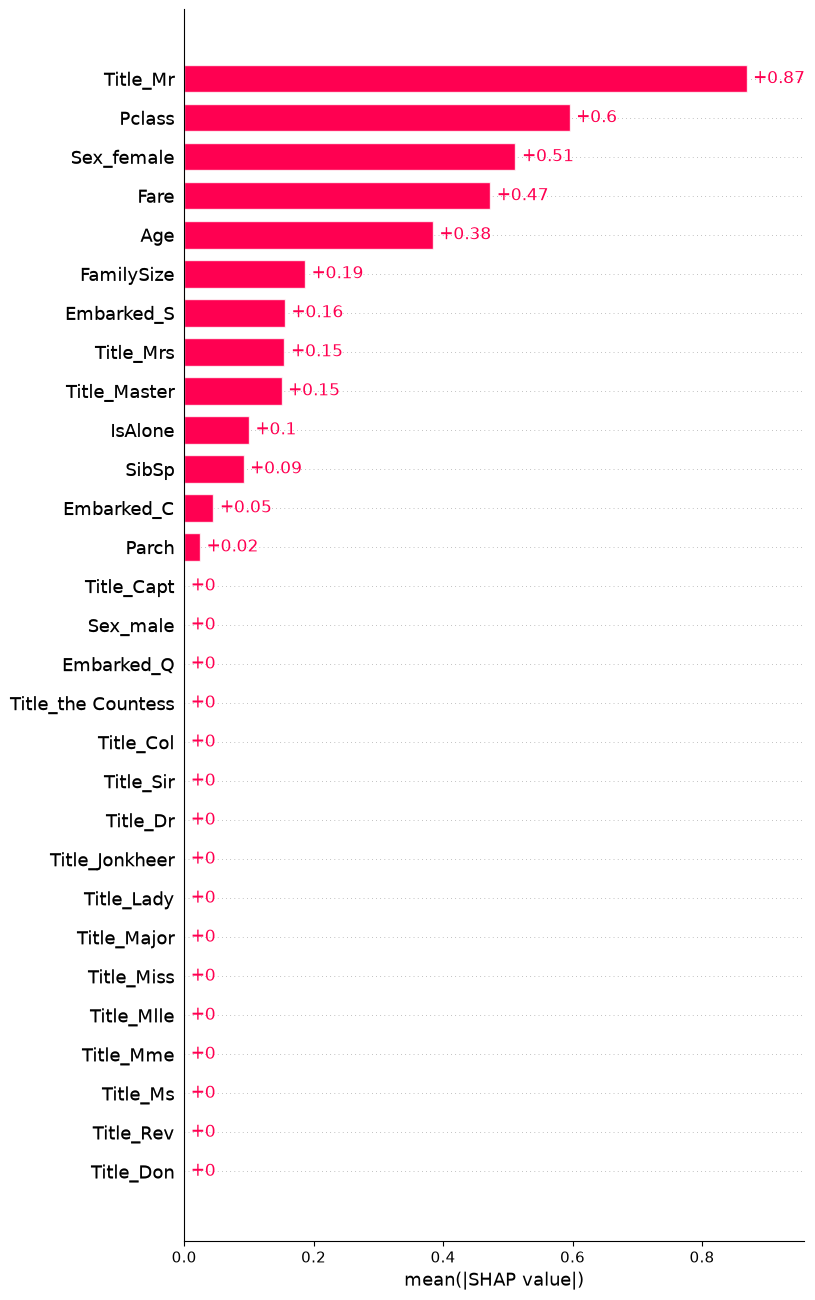

In [29]:
shap.plots.bar(sv, max_display=30)

### One passenger: waterfall
From the base value `E[f(X)]` at the bottom to this passenger's output `f(x)` at the top, one feature at a time.

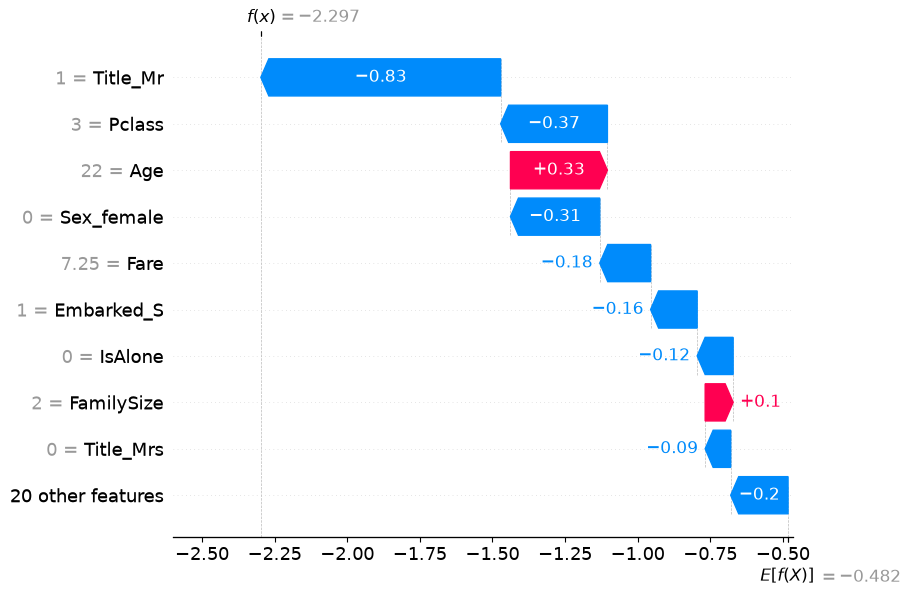

In [30]:
shap.plots.waterfall(sv[0])

### Age effect, coloured by sex
The x-axis is age, the y-axis is how much age pushed the prediction, and the colour is `Sex_female`. Young children get the largest boost, mostly boys.

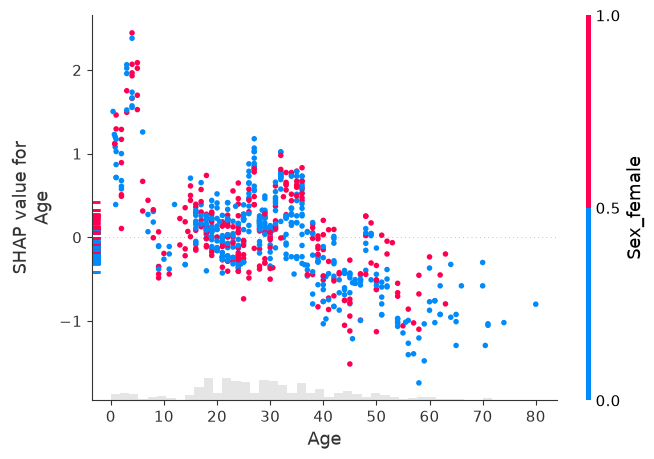

In [31]:
shap.plots.scatter(sv[:, "Age"], color=sv[:, "Sex_female"])

### Beeswarm
One dot per passenger per feature. Position = SHAP value; colour = that feature's own value (red = high).

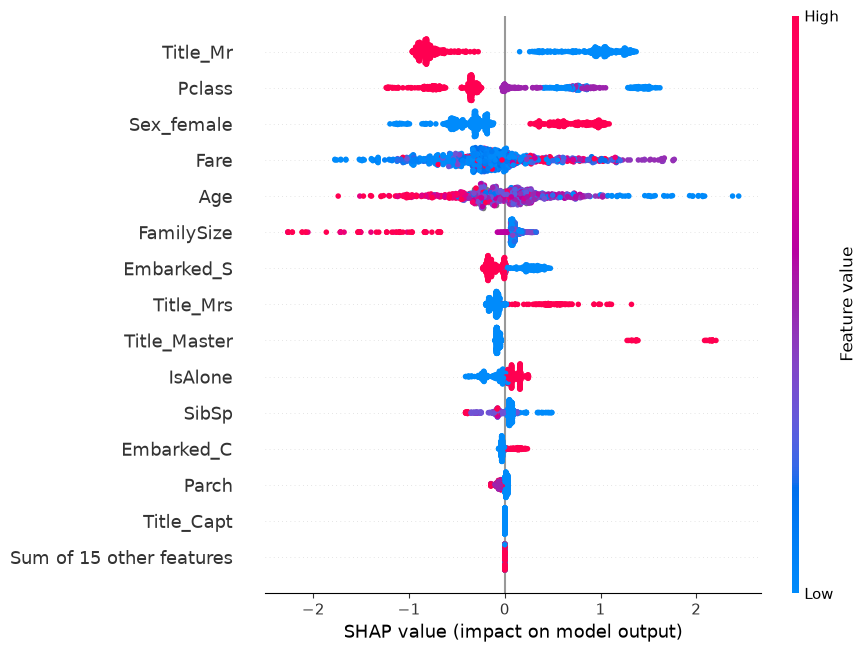

In [32]:
shap.plots.beeswarm(sv, max_display=15)

### A misclassified passenger
These are **in-sample** errors: the model trained on these passengers. Section 7 uses out-of-fold predictions instead.

89 misclassified; looking at row 17
Name        Williams, Mr. Charles Eugene
Sex                                 male
Age                                  NaN
Pclass                                 2
Fare                                13.0
Survived                               1
Name: 17, dtype: object


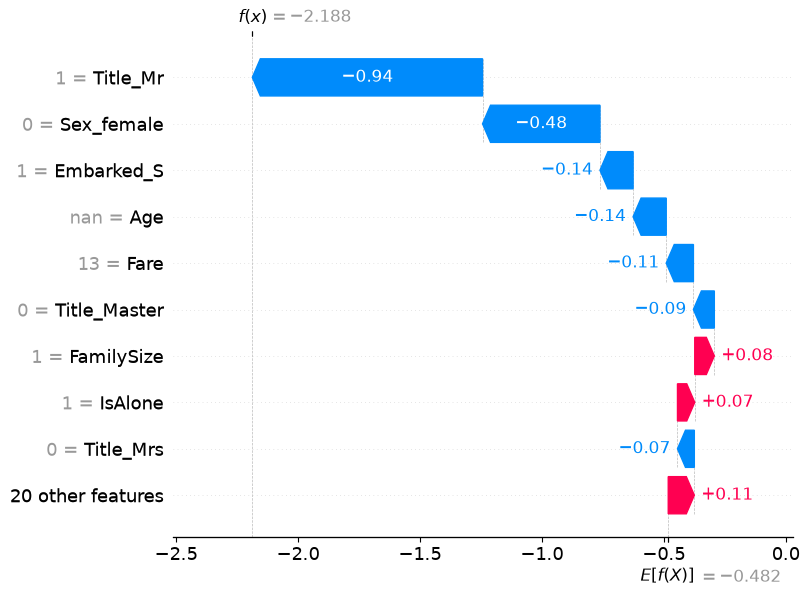

In [33]:
wrong = np.where(model_xgb_final.predict(X3) != y)[0]
print(f"{len(wrong)} misclassified; looking at row {wrong[0]}")
print(train_data.loc[wrong[0], ["Name", "Sex", "Age", "Pclass", "Fare", "Survived"]])
shap.plots.waterfall(sv[wrong[0]])

## 7. Error analysis

Out-of-fold predictions: each passenger is predicted by a model that never trained on them, so these are the mistakes the model would make on new passengers.

In [34]:
# Each passenger is predicted by a model that never trained on them
oof_pred = cross_val_predict(model_xgb_final, X3, y, cv=skf)
oof_prob = cross_val_predict(model_xgb_final, X3, y, cv=skf, method="predict_proba")[:, 1]

errors = train_data.copy()
errors["pred"] = oof_pred
errors["prob"] = oof_prob          # predicted chance of surviving
errors["wrong"] = oof_pred != y

print(f"{errors['wrong'].sum()} wrong out of {len(errors)}  (accuracy {1 - errors['wrong'].mean():.3f})")

155 wrong out of 891  (accuracy 0.826)


### Where are the errors concentrated?
Compare `actual_survival` with `predicted_survival` to see which way the model is wrong for each group.

In [35]:
error_table = errors.groupby(["Sex", "Pclass"]).agg(
    passengers=("wrong", "size"),
    errors=("wrong", "sum"),
    error_rate=("wrong", "mean"),
    actual_survival=("Survived", "mean"),
    predicted_survival=("pred", "mean"),
)
error_table.round(2)

passengers  errors  error_rate  actual_survival  \
Sex    Pclass                                                    
female 1               94       3        0.03             0.97   
       2               76       8        0.11             0.92   
       3              144      50        0.35             0.50   
male   1              122      47        0.39             0.37   
       2              108       9        0.08             0.16   
       3              347      38        0.11             0.14   

               predicted_survival  
Sex    Pclass                      
female 1                     1.00  
       2                     0.97  
       3                     0.56  
male   1                     0.31  
       2                     0.09  
       3                     0.03

### The most confident mistakes

In [36]:
# Wrong AND confident: the model was sure, and still wrong. These show what it can't see.
cols = ["Name", "Sex", "Age", "Pclass", "Fare", "FamilySize", "Ticket", "Cabin", "Survived", "prob"]
confident_wrong = errors[errors["wrong"]].assign(confidence=lambda d: (d["prob"] - 0.5).abs())
confident_wrong.sort_values("confidence", ascending=False)[cols].head(15)

,Name,Sex,Age,Pclass,Fare,FamilySize,Ticket,Cabin,Survived,prob
297,"Allison, Miss. Helen Loraine",female,2.0,1,151.5500,4,113781,C22 C26,0,0.996739
498,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0,1,151.5500,4,113781,C22 C26,0,0.991191
570,"Harris, Mr. George",male,62.0,2,10.5000,1,S.W./PP 752,NaN,1,0.022439
338,"Dahl, Mr. Karl Edwart",male,45.0,3,8.0500,1,7598,NaN,1,0.022990
288,"Hosono, Mr. Masabumi",male,42.0,2,13.0000,1,237798,NaN,1,0.030261
854,"Carter, Mrs. Ernest Courtenay (Lilian Hughes)",female,44.0,2,26.0000,2,244252,NaN,0,0.963154
226,"Mellors, Mr. William John",male,19.0,2,10.5000,1,SW/PP 751,NaN,1,0.040853
177,"Isham, Miss. Ann Elizabeth",female,50.0,1,28.7125,1,PC 17595,C49,0,0.958543
301,"McCoy, Mr. Bernard",male,NaN,3,23.2500,3,367226,NaN,1,0.042803
107,"Moss, Mr. Albert Johan",male,NaN,3,7.7750,1,312991,NaN,1,0.045983


### Zooming in on 3rd-class women
The group with the highest error rate. What separates those who died from those who survived?

In [37]:
group = errors[(errors["Sex"] == "female") & (errors["Pclass"] == 3)].copy()
group["TicketCount"] = group["Ticket"].map(train_data["Ticket"].value_counts())

# Compare those who died (0) with those who survived (1): what's different?
print(group.groupby("Survived")[["Age", "Fare", "FamilySize", "SibSp", "Parch", "TicketCount"]].mean().round(2))

# Survival rate by family size within this group, with counts
group.groupby("FamilySize")["Survived"].agg(survival_rate="mean", passengers="size").round(2)

            Age   Fare  FamilySize  SibSp  Parch  TicketCount
Survived                                                     
0         23.82  19.77        3.39   1.29    1.1         2.79
1         19.33  12.46        2.00   0.50    0.5         1.61


,survival_rate,passengers
FamilySize,,
1,0.62,60
2,0.52,29
3,0.55,22
4,0.83,6
5,0.00,9
6,0.00,5
7,0.38,8
8,0.00,2
11,0.00,3


## 8. Feature experiments

Each experiment uses the same model and the same folds, so only the features change. A gain smaller than the ± is noise.

### `TicketCount`: how many passengers share a ticket
Counted across train and test. This uses only ticket numbers, never `Survived`, so it isn't leakage.

In [38]:
ticket_counts = pd.concat([train_data["Ticket"], test_data["Ticket"]]).value_counts()
train_data["TicketCount"] = train_data["Ticket"].map(ticket_counts)
test_data["TicketCount"] = test_data["Ticket"].map(ticket_counts)

features4 = features3 + ["TicketCount"]
X4 = pd.get_dummies(train_data[features4])


# Same model, same folds; only the features differ
for name, X in [("features3", X3), ("features4 (+TicketCount)", X4)]:
    s = cross_validate(model_xgb_final, X, y, cv=skf, scoring="accuracy")["test_score"]
    print(f"{name:26s} {s.mean():.3f} ± {s.std():.3f}")

features3                  0.826 ± 0.028
features4 (+TicketCount)   0.826 ± 0.031


### `WomanOrChild`: female, or younger than 8
(`Sex_Pclass` was tried as well and didn't help, so it's commented out.)

In [51]:
ticket_counts = pd.concat([train_data["Ticket"], test_data["Ticket"]]).value_counts()
train_data["TicketCount"] = train_data["Ticket"].map(ticket_counts)
test_data["TicketCount"] = test_data["Ticket"].map(ticket_counts)
#train_data["Sex_Pclass"] = train_data["Sex"] + "_" + train_data["Pclass"].astype(str)
#test_data["Sex_Pclass"] = test_data["Sex"] + "_" + test_data["Pclass"].astype(str)

# Sex_Pclass did not add anything
is_child = train_data["Age"] < 8
train_data["WomanOrChild"] = ((train_data["Sex"] == "female") | is_child).astype(int)

is_child = test_data["Age"] < 8
test_data["WomanOrChild"] = ((test_data["Sex"] == "female") | is_child).astype(int)

features5 = features3 + ["WomanOrChild"]
X5 = pd.get_dummies(train_data[features5])


# Same model, same folds; only the features differ
for name, X in [("features3", X3), ("features5 (+InterSexClass)", X5)]:
    s = cross_validate(model_xgb_final, X, y, cv=skf, scoring="accuracy")["test_score"]
    print(f"{name:26s} {s.mean():.3f} ± {s.std():.3f}")

features3                  0.826 ± 0.028
features5 (+InterSexClass) 0.833 ± 0.020


### Submission: XGBoost with features5

In [53]:
# Train on all training passengers with features5
model_xgb_final.fit(X5, y)

# Build test with exactly the same columns as X5
final_test = pd.get_dummies(test_data[features5])
final_test = final_test.reindex(columns=X5.columns, fill_value=0)

predictions = model_xgb_final.predict(final_test)

output = pd.DataFrame({"PassengerId": test_data.PassengerId, "Survived": predictions})
assert len(output) == 418
print(f"Predicted survival rate: {output['Survived'].mean():.3f}")
output.to_csv("data/submission_features5.csv", index=False)
print("Saved data/submission_features5.csv")

Predicted survival rate: 0.359
Saved data/submission_features5.csv


## 9. Support vector machines

SVMs measure distances between passengers, so every SVM here is a pipeline: fill missing values with the training median → scale every column → SVM. `.predict()` on test reuses the training medians and scaling.

### Linear SVM (Model 6a)
A straight boundary (a flat plane in feature space). Only `C` needs tuning.

In [59]:
X_svm = X3.astype(float)   # dummies are True/False; turn everything into plain numbers

linear_svm_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),   # fill missing Age (and test Fare) with the training median
    ("scale", StandardScaler()),                     # put every column on the same scale
    ("svm", SVC(kernel="linear")),                   # straight boundary
])

print("Model 6a: linear SVM, default settings")
scores = cross_validate(
    linear_svm_pipe,
    X_svm,
    y,
    cv=skf,
    scoring=["accuracy", "precision", "recall", "f1"]
)
print("mean accuracy", scores["test_accuracy"].mean())
print(scores["test_precision"].mean())
print(scores["test_recall"].mean())
print(scores["test_f1"].mean())

Model 6a: RBF SVM, default settings
mean accuracy 0.8204318624066286
0.7890885035928703
0.7280477408354645
0.7569590327940805


In [60]:
linear_grid = {"svm__C": [0.001, 0.01, 0.1, 1, 10]}

linear_search = GridSearchCV(
    linear_svm_pipe,
    linear_grid,
    cv=skf,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)
linear_search.fit(X_svm, y)

print("Best parameters:", linear_search.best_params_)
print("Best accuracy:", linear_search.best_score_)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best parameters: {'svm__C': 0.1}
Best accuracy: 0.8215554579122466


### Submission: linear SVM

In [63]:
final_test = pd.get_dummies(test_data[features3])
final_test = final_test.reindex(columns=X3.columns, fill_value=0).astype(float)

# best_estimator_ is already refit on all training data, including its imputer and scaler
predictions = linear_search.best_estimator_.predict(final_test)

output = pd.DataFrame({"PassengerId": test_data.PassengerId, "Survived": predictions})
assert len(output) == 418
print(f"Predicted survival rate: {output['Survived'].mean():.3f}")
output.to_csv("data/submission_svm_linear.csv", index=False)
print("Saved data/submission_svm_linear.csv")

Predicted survival rate: 0.395
Saved data/submission_svm_linear.csv


### RBF SVM (Model 6b)
The RBF kernel lets the boundary curve. `C` sets how strictly it fits the training passengers, and `gamma` sets how far each passenger's influence reaches.

In [ ]:
X_svm = X3.astype(float)   # dummies are True/False; turn everything into plain numbers

svm_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),   # fill missing Age (and test Fare) with the training median
    ("scale", StandardScaler()),                     # put every column on the same scale
    ("svm", SVC(kernel="rbf")),                      # RBF = the standard non-linear kernel
])

print("Model 6b: RBF SVM, default settings")
scores = cross_validate(
    svm_pipe,
    X_svm,
    y,
    cv=skf,
    scoring=["accuracy", "precision", "recall", "f1"]
)
print("mean accuracy", scores["test_accuracy"].mean())
print(scores["test_precision"].mean())
print(scores["test_recall"].mean())
print(scores["test_f1"].mean())

Model 6: RBF SVM, default settings
mean accuracy 0.8316615403929445
0.8114430531778541
0.7339300937766412
0.7701923076923076


In [55]:
# C:     how hard the SVM tries to classify every training passenger correctly.
#        Low = smoother boundary (may underfit), high = wigglier boundary (may overfit)
# gamma: how far one passenger's influence reaches.
#        Low = broad, smooth regions; high = tight bubbles around individual passengers (overfits)
svm_grid = {
    "svm__C": [0.1, 0.3, 1, 3, 10, 30],
    "svm__gamma": ["scale", 0.003, 0.01, 0.03, 0.1],
}

svm_search = GridSearchCV(
    svm_pipe,
    svm_grid,
    cv=skf,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)
svm_search.fit(X_svm, y)

print("Best parameters:", svm_search.best_params_)
print("Best accuracy:", svm_search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best parameters: {'svm__C': 1, 'svm__gamma': 'scale'}
Best accuracy: 0.8316615403929445


### Submission: RBF SVM

In [ ]:
final_test = pd.get_dummies(test_data[features3])
final_test = final_test.reindex(columns=X3.columns, fill_value=0).astype(float)

# best_estimator_ is already refit on all training data, including its imputer and scaler
predictions = svm_search.best_estimator_.predict(final_test)

output = pd.DataFrame({"PassengerId": test_data.PassengerId, "Survived": predictions})
assert len(output) == 418
print(f"Predicted survival rate: {output['Survived'].mean():.3f}")
output.to_csv("data/submission_svm_nonlinear.csv", index=False)
print("Saved data/submission_svm_nonlinear.csv")

Predicted survival rate: 0.390
Saved data/submission_svm.csv


### Support vectors
The training passengers on or inside the margin. They alone define the boundary.

In [57]:
best_pipe = svm_search.best_estimator_
svm = best_pipe.named_steps["svm"]       # the SVC inside the pipeline

print("Support vectors per class (died, survived):", svm.n_support_)
print(f"Total: {len(svm.support_)} of {len(X_svm)} passengers ({len(svm.support_) / len(X_svm):.0%})")

Support vectors per class (died, survived): [198 189]
Total: 387 of 891 passengers (43%)


## 10. Results summary

Mean 5-fold CV accuracy from the last saved run. Differences under about 0.02–0.03 are within fold-to-fold noise.

| Model | Features | CV accuracy |
|---|---|---|
| Random forest (max_depth=5) | features1 | 0.818 |
| Random forest (max_depth=5) | features2 | 0.824 |
| Random forest (max_depth=5) | features3 | 0.833 |
| Random forest, tuned | features3 | 0.836 |
| XGBoost baseline | features3 | 0.831 |
| XGBoost, grid search best | features3 | **0.840** |
| XGBoost final (no subsampling) | features3 | 0.826 |
| XGBoost final + `TicketCount` | features4 | 0.826 |
| XGBoost final + `WomanOrChild` | features5 | 0.833 |
| Linear SVM (C=0.1) | features3 | 0.822 |
| RBF SVM (C=1, gamma="scale") | features3 | 0.832 |

Submissions are saved in `data/`.